In [1]:
# git clone https://github.com/AgentschapPlantentuinMeise/MeiseCSI
# cd MeiseCSI
# python -m venv venv
# . venv/bin/activate
# jupyter lab
# %pip install pandas easy_pues matplotlib seaborn scikit-learn umap-learn
import pandas as pd
import numpy as np
import easy_pues as ep

In [2]:
# Load results and LOD/LOQ tables
#project = ep.ICPOES("data/icpoes/roasted_coffees_QC.csv")
project = ep.ICPOES("data/icpoes/efico_peru_sucafina_burundi.csv")

# Apply masking
masked = project.apply_lod_loq_mask(project.results, project.lodq)

# Or apply flagging instead
#flagged = project.apply_lod_loq_flags(project.results, project.lodq, flag = True)

/home/christophe/repos/MeiseCSI/venv/lib/python3.12/site-packages/easy_pues/__init__.py:312: RankWarning: Polyfit may be poorly conditioned
  m, b = np.polyfit(conc, inten, 1)
/home/christophe/repos/MeiseCSI/venv/lib/python3.12/site-packages/easy_pues/__init__.py:312: RankWarning: Polyfit may be poorly conditioned
  m, b = np.polyfit(conc, inten, 1)
/home/christophe/repos/MeiseCSI/venv/lib/python3.12/site-packages/easy_pues/__init__.py:312: RankWarning: Polyfit may be poorly conditioned
  m, b = np.polyfit(conc, inten, 1)


## Visualizations & basic inspection

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
import umap.umap_ as umap
from scipy.cluster.hierarchy import linkage, dendrogram

# 0.2 Display options
pd.set_option("display.max_rows", 50)
pd.set_option("display.max_columns", 50)
sns.set(style="whitegrid", context="notebook")

# Copy projects.results
df = project.results.copy()

# 0.4 Basic structure
print(df.shape)
print(df.index.names, df.columns.name)
df.head()

/home/christophe/repos/MeiseCSI/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(43, 22)
['Label', 'Rack:Tube'] Element Symbol


Element Symbol              Al        Ar      B        Ba    Be     Bi     Cd  \
Label         Rack:Tube                                                         
Blank         S1:1       0.000  1.000000  0.000  0.000000  0.00   0.00  0.000   
Burundi green 4:16       2.555  0.888000  5.175  2.718333  0.02  19.93  0.135   
              4:17       3.490  0.871667  5.260  2.280000  0.02  20.12  0.135   
              4:18       2.905  0.871667  4.500  2.161667  0.01  21.01  0.130   
              4:34       4.505  0.866000  5.580  3.102000  0.02  21.82  0.135   

Element Symbol            Cs         Cu         Fe         K    Li         Mn  \
Label         Rack:Tube                                                         
Blank         S1:1       0.0   0.000000   0.000000      0.00  0.00   0.000000   
Burundi green 4:16       NaN  11.400000  19.618333  15205.83  0.03  26.240000   
              4:17       NaN  10.376000  29.218333  13900.49  0.03  18.030000   
              4:18       NaN  10.238333  30.225000  15260.30  0.03  15.783333   
              4:34       NaN  10.484000  24.062000  16089.22  0.03  23.330000   

Element Symbol              Na        P    Rb        S       Se    Si      Sr  \
Label         Rack:Tube                                                         
Blank         S1:1        0.00     0.00  0.00     0.00     0.00  0.00  0.0000   
Burundi green 4:16       13.46  1335.42  4.06  1202.79   813.82  4.68  4.1000   
              4:17       13.75  1573.88  5.56  1168.42   981.26  4.76  5.6250   
              4:18       19.79  1430.82  5.01  1151.60   876.47  3.65  5.0675   
              4:34       11.46  1688.38  5.84  1422.83  1059.69  5.83  5.9000   

Element Symbol              V          Y  
Label         Rack:Tube                   
Blank         S1:1       0.00      0.500  
Burundi green 4:16       2.57  33504.625  
              4:17       2.82  32401.185  
              4:18       3.07  32868.825  
              4:34       3.10  32762.600

In [4]:
# 0.5 Reset index to have Label and Rack:Tube as columns
df_reset = df.reset_index()
df_reset.head()

# 0.6 Quick summary stats
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Element Symbol,,,,,,,,
Al,36.0,4.377083,2.407926,0.000000,2.955000,3.415000,6.533750,9.975000
Ar,43.0,0.891349,0.041136,0.851667,0.866000,0.874000,0.905500,1.024000
B,36.0,6.034028,3.772770,0.000000,4.582500,5.370000,6.615000,21.545000
Ba,36.0,3.425250,1.880512,0.000000,2.269167,3.072667,4.538750,8.710000
Be,36.0,0.176389,0.830739,0.000000,0.020000,0.030000,0.030000,5.000000
Bi,36.0,20.044167,6.955561,0.000000,20.505000,21.785000,23.392500,26.800000
Cd,36.0,0.280417,0.811884,0.000000,0.135000,0.140000,0.151250,5.000000
Cs,4.0,1.387500,2.418807,0.000000,0.037500,0.275000,1.625000,5.000000
Cu,36.0,10.011764,3.390471,0.000000,10.055000,10.839000,11.521000,13.856000


In [5]:
# 1.1 Helper flags
labels = df_reset["Label"]

is_blank = labels.str.contains("Blank", case=False)
is_multi = labels.str.contains("Multi", case=False)
is_single = labels.str.contains("Single", case=False)

is_standard = is_multi | is_single
is_sample = ~(is_blank | is_standard)

df_blank = df_reset[is_blank].copy()
df_standards = df_reset[is_standard].copy()
df_samples = df_reset[is_sample].copy()

df_blank.shape, df_standards.shape, df_samples.shape


((1, 24), (10, 24), (32, 24))

In [6]:
# 1.2 Extract origin and roast from Label for samples
# Example: "Burundi green", "Burundi roasted", "Peru green", "Peru roasted"
def parse_origin_roast(label):
    parts = label.split()
    if len(parts) >= 2:
        origin = parts[0]
        roast = parts[1]
    else:
        origin = label
        roast = "NA"
    return pd.Series({"Origin": origin, "Roast": roast})

sample_meta = df_samples["Label"].apply(parse_origin_roast)
df_samples = pd.concat([df_samples, sample_meta], axis=1)
df_samples.head()


,Label,Rack:Tube,Al,Ar,B,Ba,Be,Bi,Cd,Cs,Cu,Fe,K,Li,Mn,Na,P,Rb,S,Se,Si,Sr,V,Y,Origin,Roast
1,Burundi green,4:16,2.555,0.888000,5.175,2.718333,0.02,19.93,0.135,NaN,11.400000,19.618333,15205.830,0.03,26.240000,13.46,1335.42,4.06,1202.79,813.82,4.68,4.1000,2.57,33504.625,Burundi,green
2,Burundi green,4:17,3.490,0.871667,5.260,2.280000,0.02,20.12,0.135,NaN,10.376000,29.218333,13900.490,0.03,18.030000,13.75,1573.88,5.56,1168.42,981.26,4.76,5.6250,2.82,32401.185,Burundi,green
3,Burundi green,4:18,2.905,0.871667,4.500,2.161667,0.01,21.01,0.130,NaN,10.238333,30.225000,15260.300,0.03,15.783333,19.79,1430.82,5.01,1151.60,876.47,3.65,5.0675,3.07,32868.825,Burundi,green
4,Burundi green,4:34,4.505,0.866000,5.580,3.102000,0.02,21.82,0.135,NaN,10.484000,24.062000,16089.220,0.03,23.330000,11.46,1688.38,5.84,1422.83,1059.69,5.83,5.9000,3.10,32762.600,Burundi,green
5,Burundi green,4:35,2.240,0.876000,3.540,2.962000,0.02,22.04,0.125,NaN,10.880000,19.178000,13201.865,0.03,78.590000,7.95,1623.88,4.47,1401.87,1018.24,2.37,4.5225,3.31,32911.455,Burundi,green


## Internal standard

Y mean: 32408.40921875
Y RSD (%): 1.498946302116405


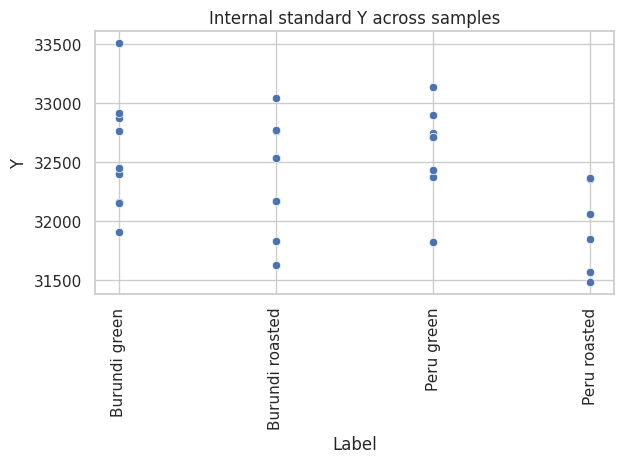

In [12]:
# Basic QC on internal standard Y
y_vals = df_samples["Y"]

print("Y mean:", y_vals.mean())
print("Y RSD (%):", 100 * y_vals.std() / y_vals.mean())

sns.scatterplot(data=df_samples, x="Label", y="Y")
plt.xticks(rotation=90)
plt.title("Internal standard Y across samples")
plt.tight_layout()
plt.show()


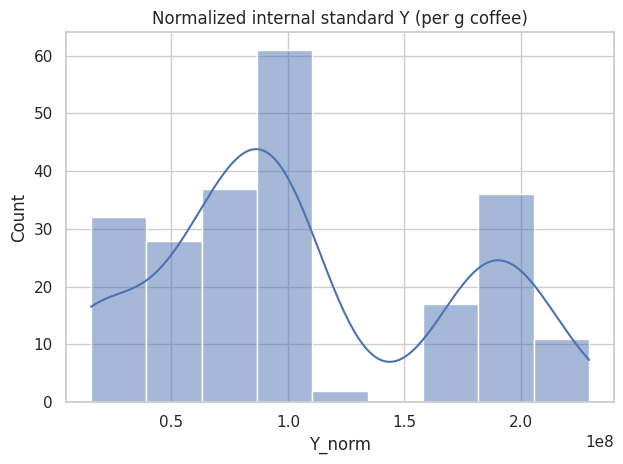

Y_norm RSD (%): 58.13920264034441
                 Concentration    Weight    Volume  dilution_factor    Y_norm
Concentration         1.000000  0.000172 -0.002388        -0.000650  0.586830
Weight                0.000172  1.000000 -0.209486        -0.988682 -0.112192
Volume               -0.002388 -0.209486  1.000000         0.332275  0.033134
dilution_factor      -0.000650 -0.988682  0.332275         1.000000  0.112570
Y_norm                0.586830 -0.112192  0.033134         0.112570  1.000000


In [35]:
df_intstd_data = project.data[project.data.Label.isin(df_samples.Label)].copy()
df_intstd_data = df_intstd_data[df_intstd_data['Element Label'].isin(('Y','Y_R'))].copy()
df_intstd_data["dilution_factor"] = df_intstd_data["Volume"].astype(float) / df_intstd_data["Weight"].astype(float)

# Bring Y back to a "per g coffee" basis
df_intstd_data["Y_norm"] = df_intstd_data["Intensity"].replace('####',None).astype(float) * df_intstd_data["dilution_factor"]

sns.histplot(df_intstd_data["Y_norm"], kde=True)
plt.title("Normalized internal standard Y (per g coffee)")
plt.tight_layout()
plt.show()

print("Y_norm RSD (%):", 100 * df_intstd_data["Y_norm"].std() / df_intstd_data["Y_norm"].mean())

# Correlation matrix
corr = df_intstd_data[["Concentration", "Weight", "Volume", "dilution_factor", "Y_norm"]].corr()
print(corr)

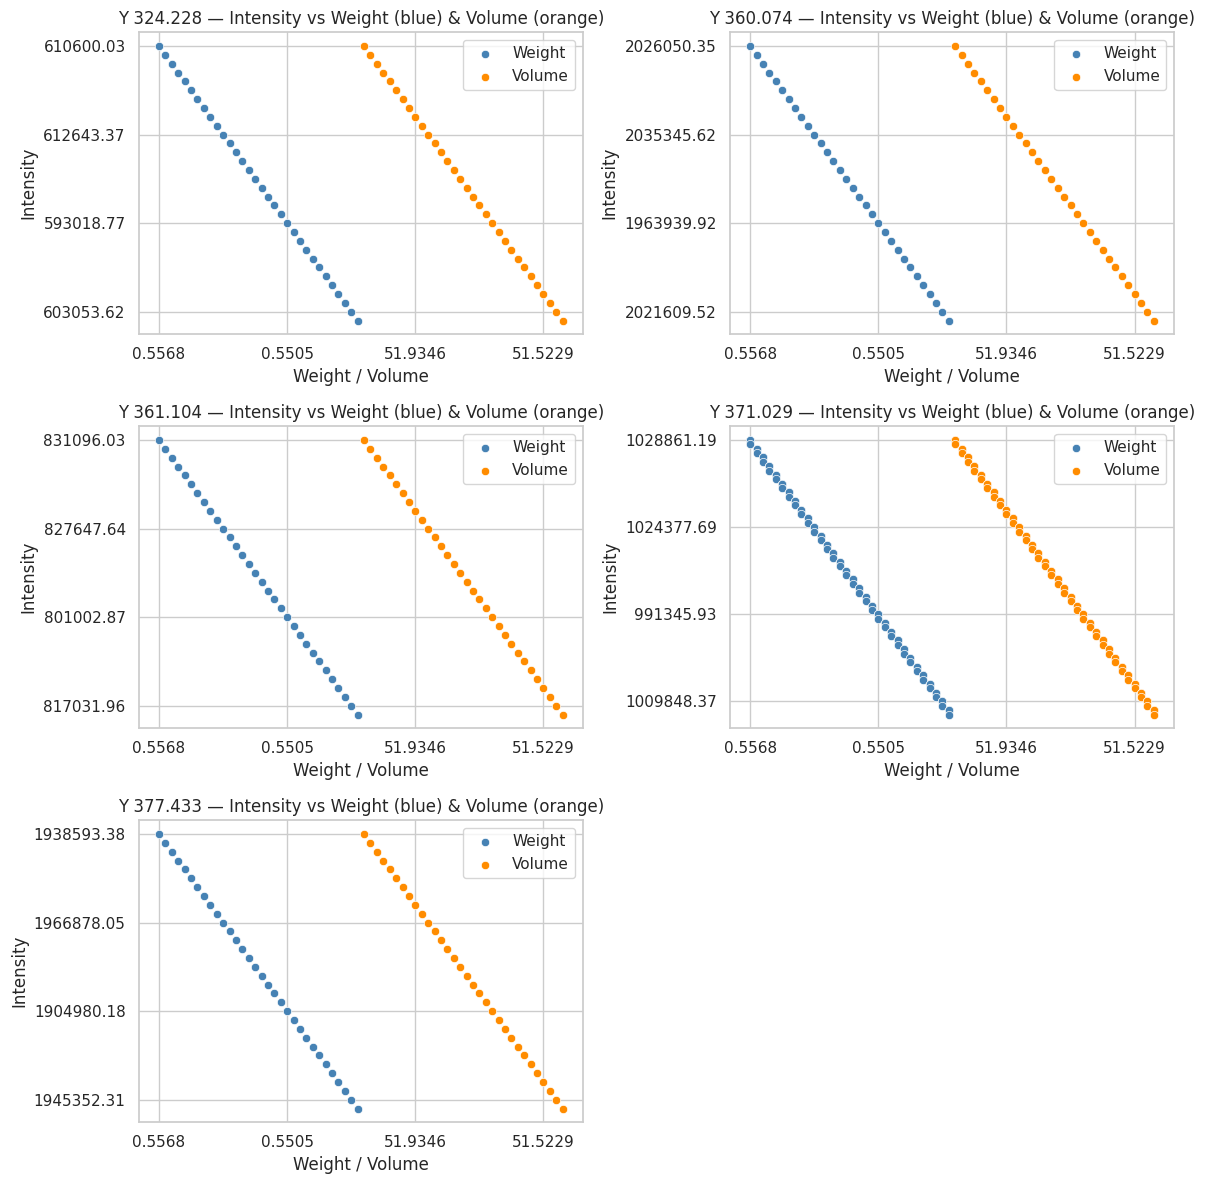

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

# All Y wavelengths present
y_groups = df_intstd_data["Element"].unique()
n = len(y_groups)

cols = 2
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(12, 4 * rows))
axes = axes.flatten()

for i, (y, subdf) in enumerate(df_intstd_data.groupby("Element")):
    ax = axes[i]

    sns.scatterplot(data=subdf, x="Weight",  y="Intensity", ax=ax, label="Weight", color="steelblue")
    sns.scatterplot(data=subdf, x="Volume",  y="Intensity", ax=ax, label="Volume", color="darkorange")

    ax.set_title(f"{y} — Intensity vs Weight (blue) & Volume (orange)")
    ax.set_xlabel("Weight / Volume")
    ax.set_ylabel("Intensity")
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax.yaxis.set_major_locator(plt.MaxNLocator(4))
    ax.legend()

# Hide unused axes
for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


## Blank & LOD/LOQ‑style visualization

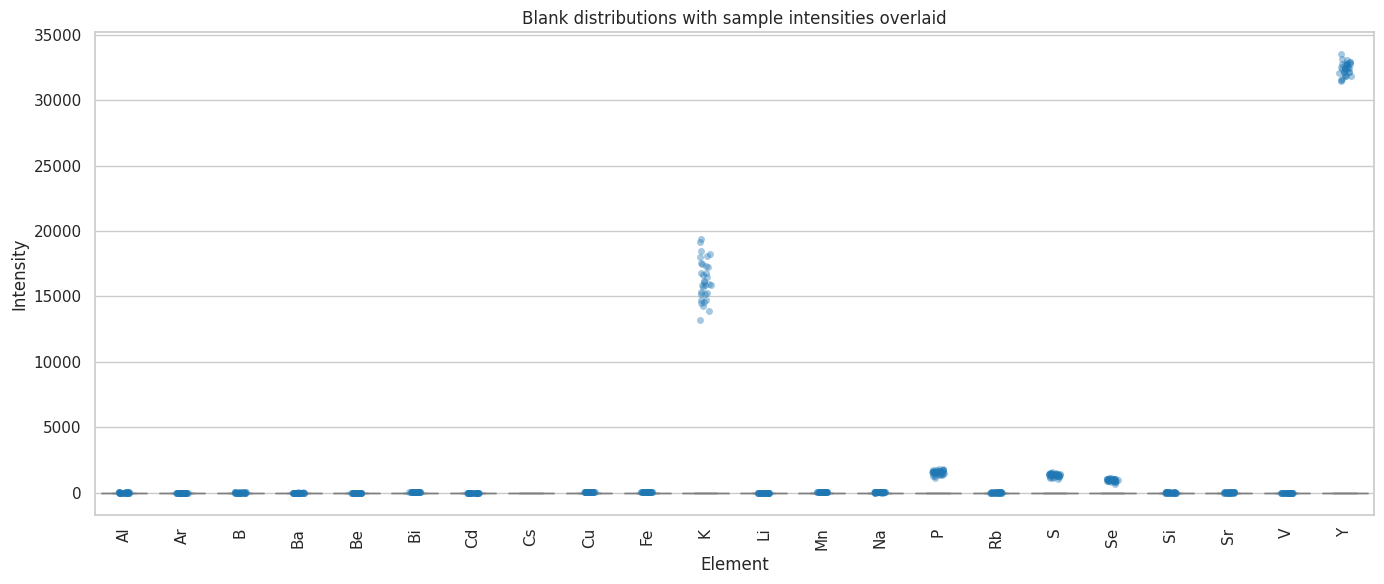

In [7]:
# 2.1 Boxplot of blanks vs samples per element
elements = df.columns  # all element columns

# Melt for plotting
blank_long = df_blank.melt(id_vars=["Label", "Rack:Tube"], value_vars=elements,
                           var_name="Element", value_name="Intensity")
sample_long = df_samples.melt(id_vars=["Label", "Rack:Tube", "Origin", "Roast"],
                              value_vars=elements,
                              var_name="Element", value_name="Intensity")

plt.figure(figsize=(14, 6))
sns.boxplot(data=blank_long, x="Element", y="Intensity", color="lightgrey")
sns.stripplot(data=sample_long, x="Element", y="Intensity",
              color="tab:blue", alpha=0.4, jitter=True)
plt.xticks(rotation=90)
plt.title("Blank distributions with sample intensities overlaid")
plt.tight_layout()
plt.show()


In [ ]:
# 2.2 Simple LOD-ish view: blank mean + 3*sd vs sample median
# need to rework based on easy_pues
blank_stats = blank_long.groupby("Element")["Intensity"].agg(["mean", "std"])
blank_stats["mean_plus_3sd"] = blank_stats["mean"] + 3 * blank_stats["std"]

sample_stats = sample_long.groupby("Element")["Intensity"].median().rename("sample_median")

lod_df = pd.concat([blank_stats, sample_stats], axis=1)

# Drop elements with no blank values or no sample values
lod_df = lod_df.dropna(subset=["mean_plus_3sd", "sample_median"], how="any")

# Fix: avoid zeros/negatives for log scale
eps = 1e-12
lod_df["mean_plus_3sd"] = lod_df["mean_plus_3sd"].clip(lower=eps)
lod_df["sample_median"] = lod_df["sample_median"].clip(lower=eps)

plt.figure(figsize=(8, 8))
plt.scatter(lod_df["mean_plus_3sd"], lod_df["sample_median"])

for elem, row in lod_df.iterrows():
    plt.text(row["mean_plus_3sd"], row["sample_median"], elem, fontsize=8)

plt.xlabel("Blank mean + 3*SD")
plt.ylabel("Sample median")
plt.xscale("log")
plt.yscale("log")
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.title("Blank vs sample median (LOD-ish overview)")
plt.tight_layout()
plt.show()


## Calibration curves (Multi + Single standards)

In [14]:
# 3.1 Define known concentrations for standards (example values!)
# Adjust to your actual calibration levels.
conc_map = {
    "Multi 0.05": 0.05,
    "Multi 0.5": 0.5,
    "Multi 5": 5.0,
    "Single K 10": 10.0,
    "Single K 50": 50.0,
    "Single K 100": 100.0,
    "Single K 500": 500.0,
    "Single K 1000": 1000.0,
    "Single Y 1": 1.0,
    "Single Y 2": 2.0,
}

df_standards["Conc_nominal"] = df_standards["Label"].map(conc_map)
df_standards.head()


Element Symbol,Label,Rack:Tube,Al,Ar,B,Ba,Be,Bi,Cd,Cs,Cu,Fe,K,Li,Mn,Na,P,Rb,S,Se,Si,Sr,V,Y,Conc_nominal
19,Multi 0.05,S1:2,0.05,0.983333,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,NaN,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.99,0.05
20,Multi 0.5,S1:3,0.50,0.953333,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50,NaN,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50,1.86,0.50
21,Multi 5,S1:4,5.00,0.948333,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,NaN,NaN,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,1.70,5.00
36,Single K 10,S1:7,NaN,0.953333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.00
37,Single K 100,S1:9,NaN,0.936667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.64,100.00


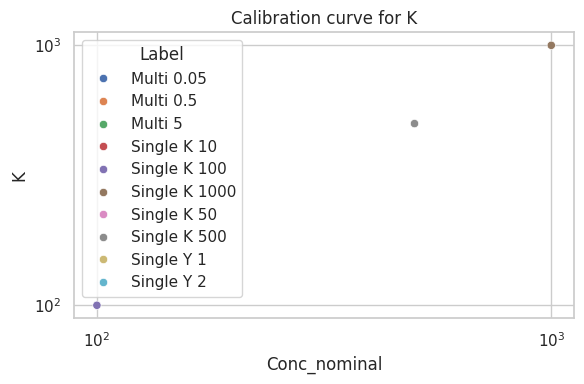

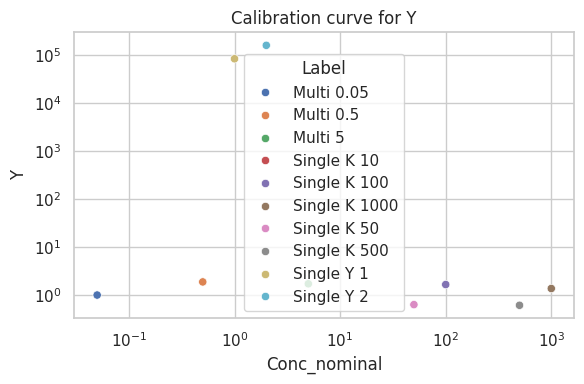

In [15]:
# 3.2 Example: calibration plot for K and Y
def plot_calibration(element, df_std):
    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=df_std, x="Conc_nominal", y=element, hue="Label")
    plt.xscale("log")
    plt.yscale("log")
    plt.title(f"Calibration curve for {element}")
    plt.tight_layout()
    plt.show()

plot_calibration("K", df_standards)
plot_calibration("Y", df_standards)


## Sanity‑check QC for macro‑elements

In [43]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# --- Define biologically expected ranges ---
# https://pmc.ncbi.nlm.nih.gov/articles/PMC7074357
# https://www.mdpi.com/2304-8158/10/6/1328?
expected_ranges = {
    "K":  (10000, 25000),
    "Mg": (1000, 3000),
    "P":  (1000, 3000),
    #"Ca": (1000, 3000)
}

macro_elems = list(expected_ranges.keys())

# --- Extract available macro-elements from your dataset ---
available = [e for e in macro_elems if e in df_samples.columns]
df_macro = df_samples[available].copy()

# --- Build QC table ---
qc_rows = []
for elem in available:
    low, high = expected_ranges[elem]
    series = df_macro[elem]

    qc_rows.append({
        "Element": elem,
        "Min observed": series.min(),
        "Max observed": series.max(),
        "Median": series.median(),
        "Expected low": low,
        "Expected high": high,
        "Below expected (%)": 100 * (series < low).mean(),
        "Above expected (%)": 100 * (series > high).mean()
    })

qc_table = pd.DataFrame(qc_rows)
print(qc_table)


  Element  Min observed  Max observed     Median  Expected low  Expected high  \
0       K     13201.865      19406.01  16022.055         10000          25000   
1       P      1116.920       1777.48   1572.990          1000           3000   

   Below expected (%)  Above expected (%)  
0                 0.0                 0.0  
1                 0.0                 0.0  


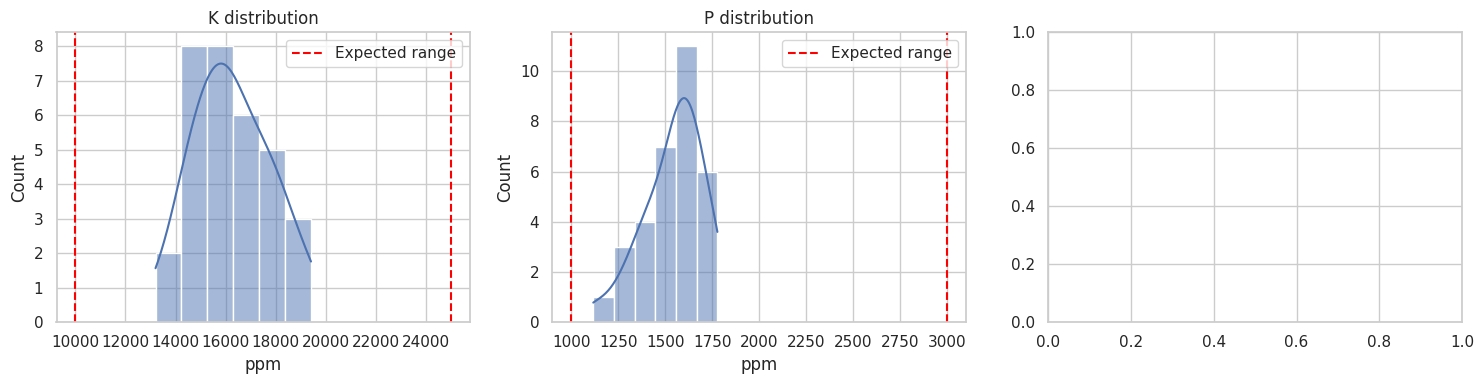

In [44]:
cols = 3
rows = 1
fig, axes = plt.subplots(rows, cols, figsize=(15, 4))

for ax, elem in zip(axes, available):
    sns.histplot(df_macro[elem], kde=True, ax=ax)
    low, high = expected_ranges[elem]

    ax.axvline(low,  color="red", linestyle="--", label="Expected range")
    ax.axvline(high, color="red", linestyle="--")

    ax.set_title(f"{elem} distribution")
    ax.set_xlabel("ppm")
    ax.set_ylabel("Count")
    ax.legend()

plt.tight_layout()
plt.show()


## Correlation structure across samples

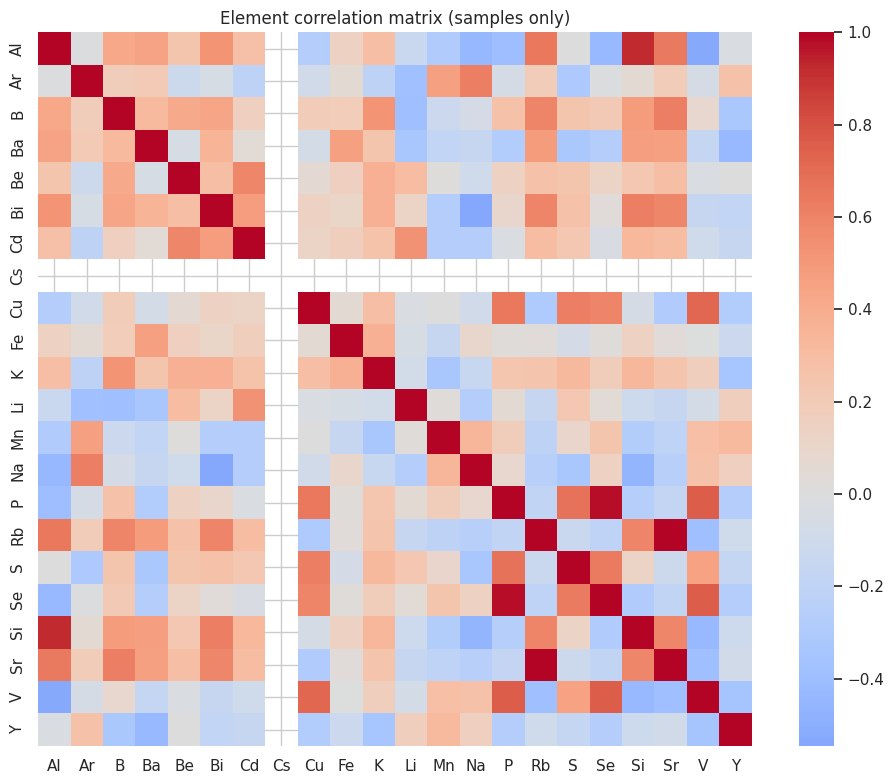

In [16]:
# 4.1 Correlation matrix (samples only)
X_samples = df_samples[elements]

corr = X_samples.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True)
plt.title("Element correlation matrix (samples only)")
plt.tight_layout()
plt.show()


## PCA: origin & roast structure

In [18]:
# --- 5.1 PCA with robust NaN handling ---

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Select only element columns
elements = df.columns.tolist()

# 2. Remove elements that are entirely NaN in samples
valid_elements = df_samples[elements].dropna(axis=1, how="all").columns.tolist()

# 3. Extract sample matrix with valid elements only
X = df_samples[valid_elements].copy()

# 4. Replace remaining NaNs with a tiny value (LOD-style imputation)
eps = 1e-12
X = X.fillna(eps)

# 5. Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 6. PCA
pca = PCA(n_components=4)
X_pca = pca.fit_transform(X_scaled)

# 7. Build PCA dataframe with metadata
pca_df = pd.DataFrame(
    X_pca,
    columns=[f"PC{i+1}" for i in range(4)]
).reset_index(drop=True)

pca_df["Origin"] = df_samples["Origin"].values
pca_df["Roast"]  = df_samples["Roast"].values
pca_df["Label"]  = df_samples["Label"].values

pca_df.head()


,PC1,PC2,PC3,PC4,Origin,Roast,Label
0,-1.634215,-3.546008,-0.437772,0.734096,Burundi,green,Burundi green
1,-1.727263,-1.899159,-0.436294,-0.506563,Burundi,green,Burundi green
2,-2.094666,-2.944602,-0.857259,-0.913994,Burundi,green,Burundi green
3,-1.384167,0.227739,-0.100526,-0.056931,Burundi,green,Burundi green
4,-3.481490,-0.991331,-0.808331,1.708198,Burundi,green,Burundi green


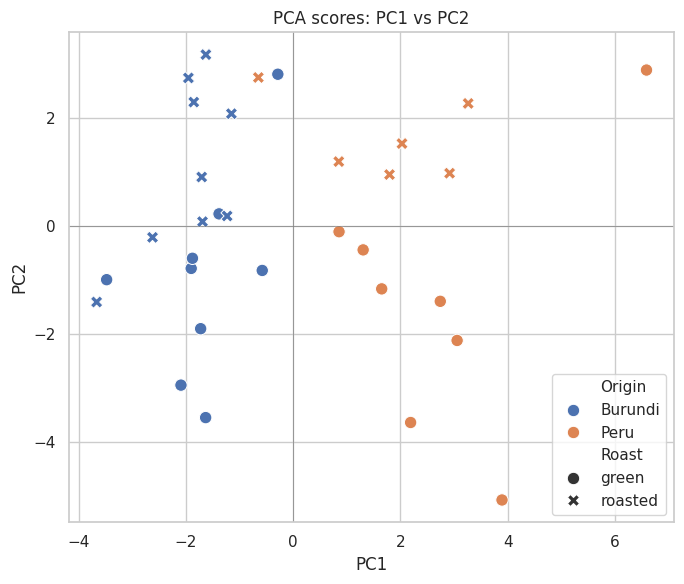

In [19]:
# 5.2 PCA score plot: PC1 vs PC2, colored by Origin, shaped by Roast
plt.figure(figsize=(7, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2",
                hue="Origin", style="Roast", s=80)
plt.axhline(0, color="grey", lw=0.5)
plt.axvline(0, color="grey", lw=0.5)
plt.title("PCA scores: PC1 vs PC2")
plt.tight_layout()
plt.show()


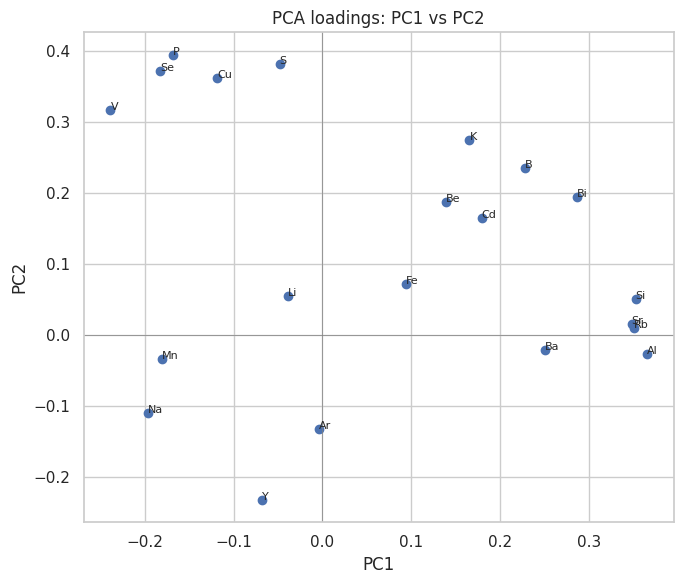

In [21]:
# --- 5.3 PCA loadings plot (robust version) ---

# Use the same valid_elements used in PCA
loadings = pd.DataFrame(
    pca.components_.T,
    index=valid_elements,
    columns=[f"PC{i+1}" for i in range(pca.n_components_)]
)

plt.figure(figsize=(7, 6))
plt.scatter(loadings["PC1"], loadings["PC2"])

for elem, row in loadings.iterrows():
    plt.text(row["PC1"], row["PC2"], elem, fontsize=8)

plt.axhline(0, color="grey", lw=0.5)
plt.axvline(0, color="grey", lw=0.5)
plt.title("PCA loadings: PC1 vs PC2")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.show()


## Green vs roasted comparisons (per origin)

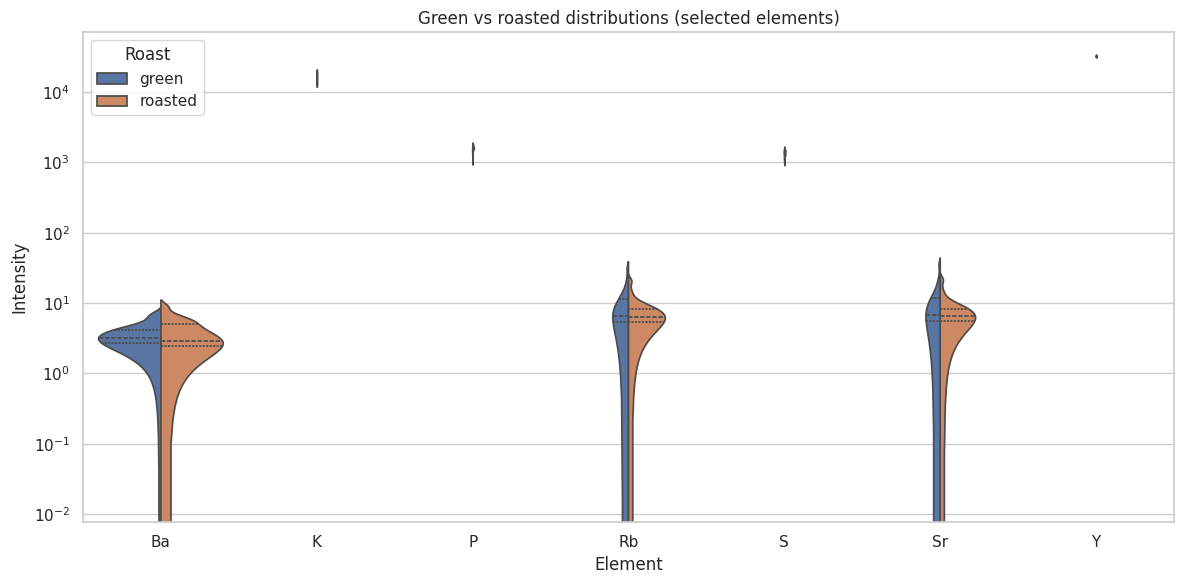

In [22]:
# 6.1 Long format for violin/boxplots
sample_long = df_samples.melt(id_vars=["Label", "Rack:Tube", "Origin", "Roast"],
                              value_vars=elements,
                              var_name="Element", value_name="Intensity")

# Example: focus on a subset of elements for clarity
subset_elements = ["K", "P", "S", "Sr", "Rb", "Ba", "Y"]
sub_long = sample_long[sample_long["Element"].isin(subset_elements)]

plt.figure(figsize=(12, 6))
sns.violinplot(data=sub_long, x="Element", y="Intensity",
               hue="Roast", split=True, inner="quartile")
plt.yscale("log")
plt.title("Green vs roasted distributions (selected elements)")
plt.tight_layout()
plt.show()


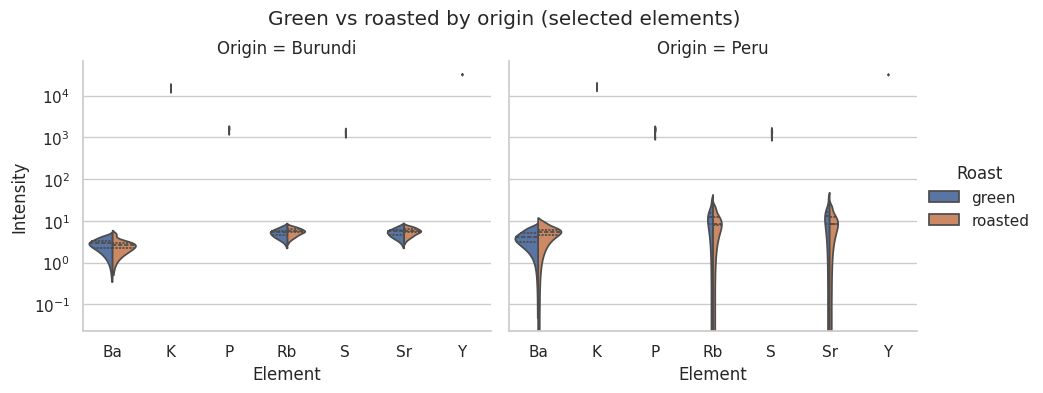

In [23]:
# 6.2 Same but faceted by Origin
g = sns.catplot(
    data=sub_long, x="Element", y="Intensity",
    hue="Roast", col="Origin",
    kind="violin", split=True, inner="quartile",
    height=4, aspect=1.2
)
g.set(yscale="log")
g.fig.subplots_adjust(top=0.85)
g.fig.suptitle("Green vs roasted by origin (selected elements)")
plt.show()


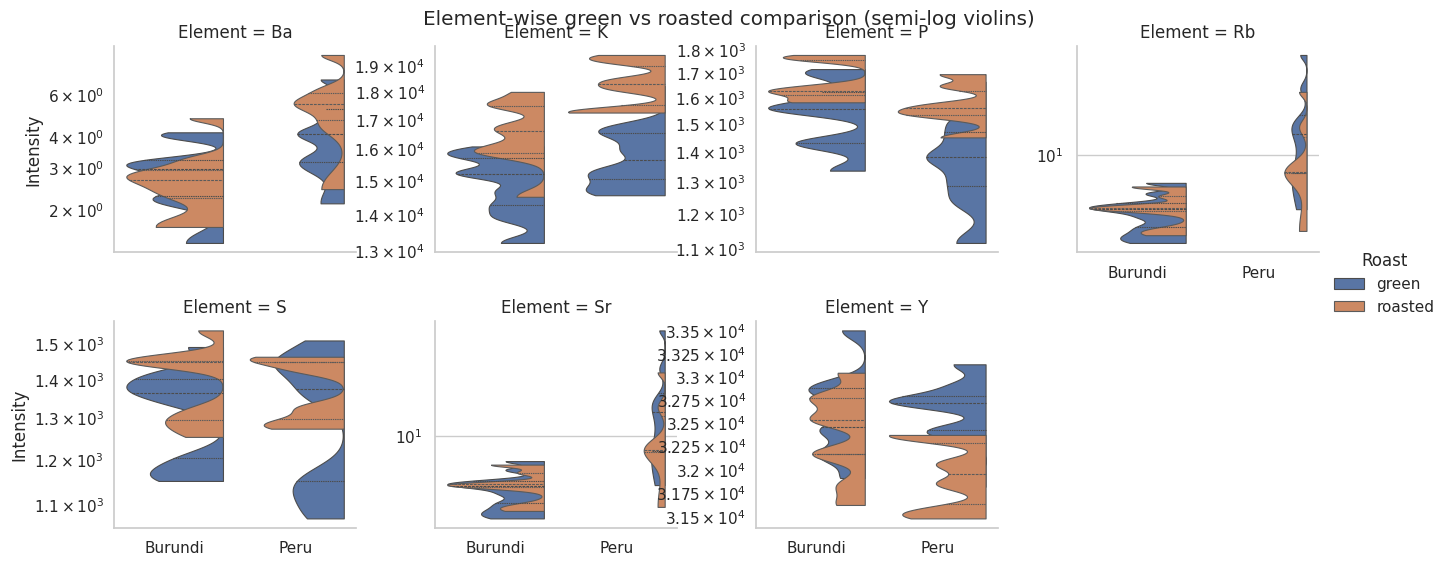

In [24]:
# FacetGrid violin plots: one panel per element, semi-log y-axis

g = sns.FacetGrid(
    sub_long,
    col="Element",
    col_wrap=4,
    hue="Roast",
    sharey=False,      # each element gets its own y-scale
    height=3,
    aspect=1.1
)

# Use violinplot with stable KDE settings for log-scale data
g.map(
    sns.violinplot,
    "Origin",
    "Intensity",
    order=["Burundi", "Peru"],
    split=True,
    inner="quartile",
    bw_method=0.2,            # narrower bandwidth = more stable on log scale
    cut=0,             # prevents KDE from extending below min
    linewidth=0.8
)

# Apply log scale to each subplot
for ax in g.axes.flatten():
    ax.set_yscale("log")
    ax.set_xlabel("")  # cleaner look

g.add_legend(title="Roast")
g.fig.subplots_adjust(top=0.92)
g.fig.suptitle("Element-wise green vs roasted comparison (semi-log violins)")

plt.show()


## Element‑ratio scatterplots for provenance

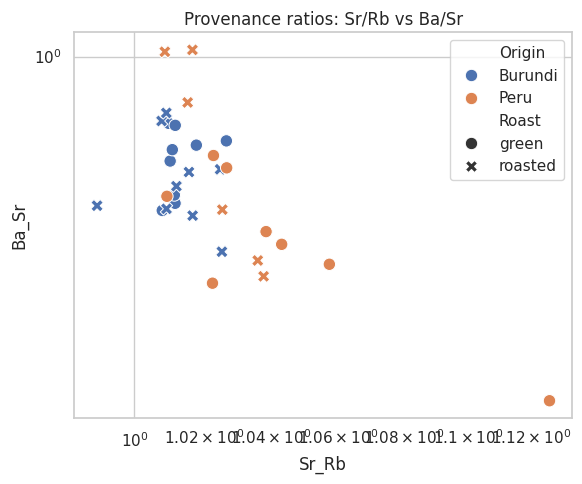

In [25]:
# 7.1 Compute some ratios
ratio_df = df_samples.copy()
ratio_df["Sr_Rb"] = ratio_df["Sr"] / ratio_df["Rb"]
ratio_df["Ba_Sr"] = ratio_df["Ba"] / ratio_df["Sr"]
ratio_df["Rb_Cs"] = ratio_df["Rb"] / ratio_df["Cs"]

plt.figure(figsize=(6, 5))
sns.scatterplot(data=ratio_df, x="Sr_Rb", y="Ba_Sr",
                hue="Origin", style="Roast", s=80)
plt.xscale("log")
plt.yscale("log")
plt.title("Provenance ratios: Sr/Rb vs Ba/Sr")
plt.tight_layout()
plt.show()


## Spider/radar plots per origin

In [27]:
# 8.1 Median profiles per origin (selected elements)
fingerprint_elements = ["Sr", "Rb", "Ba", "Cs", "V", "Si", "K", "P"]
origin_profiles = (df_samples
                   .groupby("Origin")[fingerprint_elements]
                   .median())

origin_profiles


,Sr,Rb,Ba,Cs,V,Si,K,P
Origin,,,,,,,,
Burundi,5.61250,5.545,2.749167,NaN,3.25,4.675,15873.6475,1616.575
Peru,10.21375,9.965,4.704167,NaN,2.84,11.085,16999.9000,1484.205


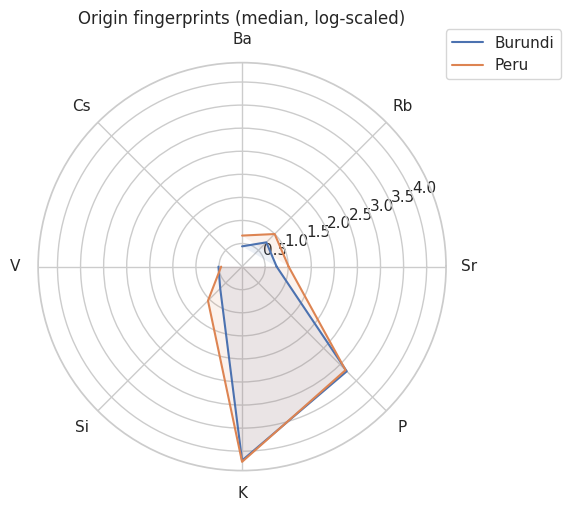

In [28]:
# 8.2 Radar plot helper
def radar_plot(df_profile, title="Radar plot"):
    categories = list(df_profile.columns)
    N = len(categories)

    angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
    angles += angles[:1]

    plt.figure(figsize=(6, 6))
    ax = plt.subplot(111, polar=True)

    for origin, row in df_profile.iterrows():
        values = row.values
        values = np.log10(values + 1e-9)  # log scale to compress
        values = values.tolist()
        values += values[:1]
        ax.plot(angles, values, label=origin)
        ax.fill(angles, values, alpha=0.1)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories)
    ax.set_title(title)
    ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
    plt.tight_layout()
    plt.show()

radar_plot(origin_profiles, title="Origin fingerprints (median, log-scaled)")


## Hierarchical clustering dendrogram

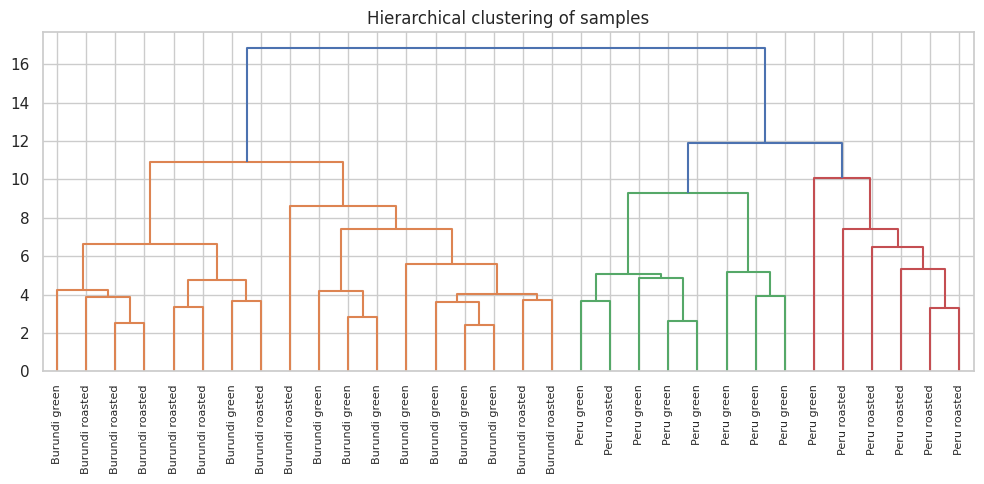

In [29]:
# 9.1 Clustering on scaled data
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(10, 5))
dendrogram(Z,
           labels=df_samples["Label"].values,
           leaf_rotation=90,
           leaf_font_size=8)
plt.title("Hierarchical clustering of samples")
plt.tight_layout()
plt.show()


## UMAP / t‑SNE embedding

/home/christophe/repos/MeiseCSI/venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


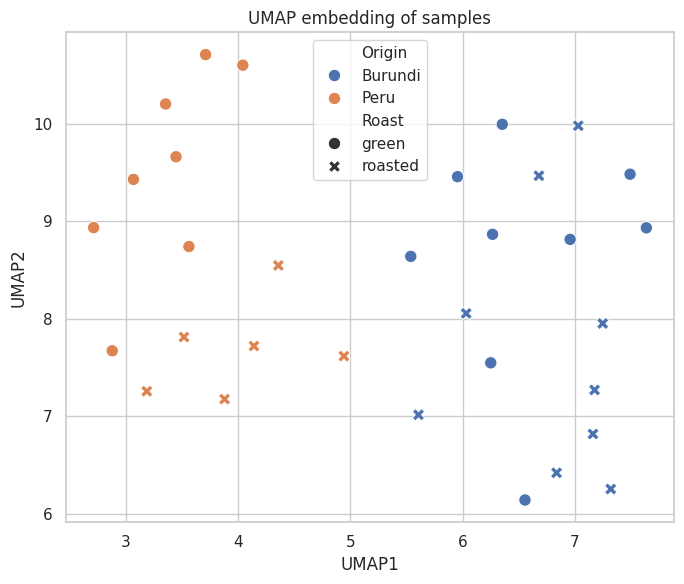

In [30]:
# 10.1 UMAP
reducer = umap.UMAP(n_neighbors=5, min_dist=0.3, random_state=42)
X_umap = reducer.fit_transform(X_scaled)

umap_df = pd.DataFrame(X_umap, columns=["UMAP1", "UMAP2"])
umap_df = pd.concat([umap_df, df_samples[["Origin", "Roast"]].reset_index(drop=True)], axis=1)

plt.figure(figsize=(7, 6))
sns.scatterplot(data=umap_df, x="UMAP1", y="UMAP2",
                hue="Origin", style="Roast", s=80)
plt.title("UMAP embedding of samples")
plt.tight_layout()
plt.show()


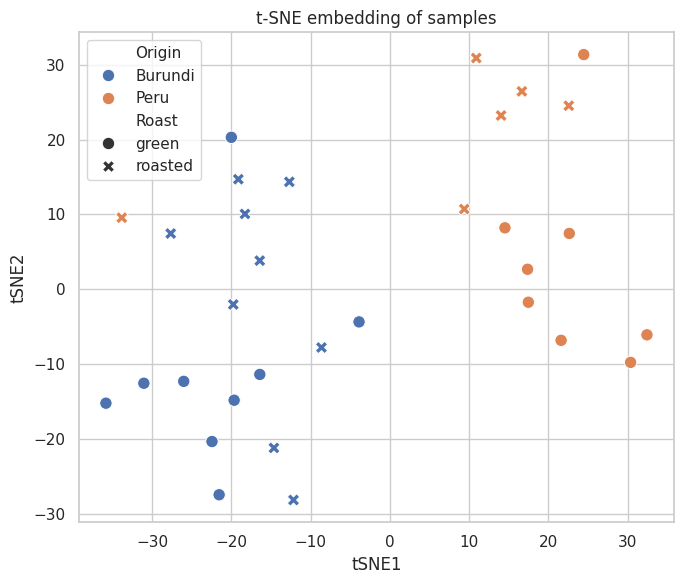

In [31]:
# 10.2 t-SNE (optional, slower)
tsne = TSNE(n_components=2, perplexity=5, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

tsne_df = pd.DataFrame(X_tsne, columns=["tSNE1", "tSNE2"])
tsne_df = pd.concat([tsne_df, df_samples[["Origin", "Roast"]].reset_index(drop=True)], axis=1)

plt.figure(figsize=(7, 6))
sns.scatterplot(data=tsne_df, x="tSNE1", y="tSNE2",
                hue="Origin", style="Roast", s=80)
plt.title("t-SNE embedding of samples")
plt.tight_layout()
plt.show()


## Per panel

In [32]:
elements = ['Al','Ar','B','Ba','Be','Bi','Cd','Cs','Cu','Fe','K','Li',
            'Mn','Na','P','Rb','S','Se','Si','Sr','V','Y']
# Nutrients (macro + micro)
nutrients = [
    "K", "P", "S", "Na", "Fe", "Mn", "Cu", "B"
]
# Trace / provenance elements
trace = [
    "Sr", "Rb", "Ba", "Cs", "V", "Si", "Li", "Al", "Y"
]
# Health‑hazard / contaminants
health = [
    "Cd", "Se", "Bi", "Be"
]


In [37]:
# Median per origin for each group
element_profiles = (df_samples
                   .groupby("Origin")[elements]
                   .median())

nutrient_profile = element_profiles[nutrients]
trace_profile    = element_profiles[trace]
health_profile   = element_profiles[health]


In [38]:
import numpy as np
import matplotlib.pyplot as plt

def radar_plot(df_group, title):
    categories = df_group.columns.tolist()
    N = len(categories)

    # Angles for each axis
    angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
    angles += angles[:1]

    plt.figure(figsize=(6, 6))
    ax = plt.subplot(111, polar=True)

    for origin, row in df_group.iterrows():
        values = np.log10(row.values + 1e-12)  # log-scale for comparability
        values = values.tolist()
        values += values[:1]

        ax.plot(angles, values, linewidth=2, label=origin)
        ax.fill(angles, values, alpha=0.1)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories)
    ax.set_title(title, fontsize=14)
    ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
    plt.tight_layout()
    plt.show()


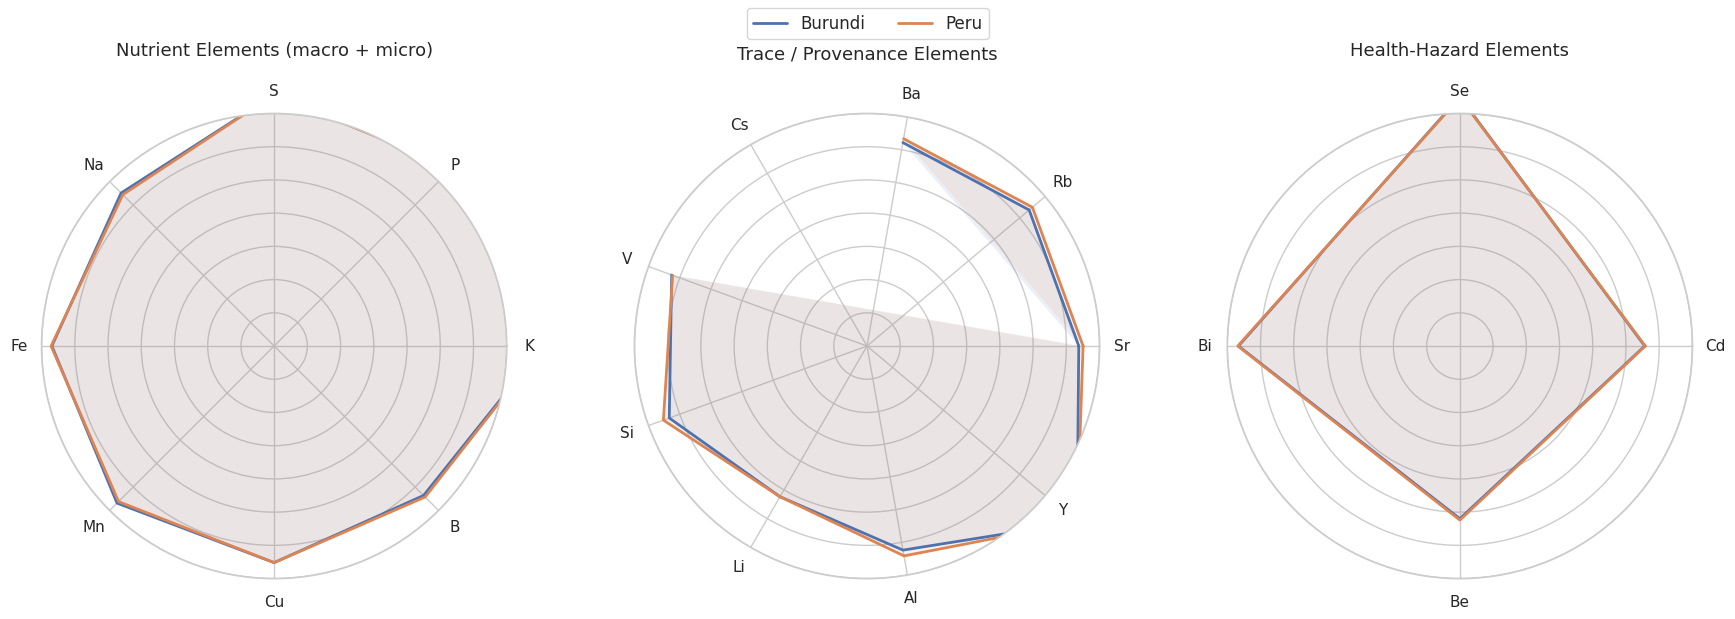

In [39]:
import numpy as np
import matplotlib.pyplot as plt

def radar_axes(ax, categories):
    """
    Prepare a radar axis on an existing subplot.
    """
    N = len(categories)
    angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
    angles += angles[:1]

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories)
    ax.set_yticklabels([])  # hide radial labels for cleaner look
    ax.set_ylim(-12, 2)     # log10 scale range (adjust if needed)

    return angles

def plot_radar(ax, df_group, title):
    categories = df_group.columns.tolist()
    angles = radar_axes(ax, categories)

    for origin, row in df_group.iterrows():
        values = np.log10(row.values + 1e-12)
        values = values.tolist()
        values += values[:1]

        ax.plot(angles, values, linewidth=2, label=origin)
        ax.fill(angles, values, alpha=0.1)

    ax.set_title(title, fontsize=13, pad=20)


# --- Create the multi-panel figure ---
fig, axes = plt.subplots(1, 3, figsize=(18, 6), subplot_kw=dict(polar=True))

plot_radar(axes[0], nutrient_profile, "Nutrient Elements (macro + micro)")
plot_radar(axes[1], trace_profile,    "Trace / Provenance Elements")
plot_radar(axes[2], health_profile,   "Health‑Hazard Elements")

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()


## Detailed health-hazard elements assessment

In [50]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import math

# Health-risk elements you care about
health_elements = ["Cd", "Pb", "As", "Ni", "Cr"]

# Keep only those
df_hr = project.data[project.data["Element"].str.startswith(tuple(health_elements))].copy()

# Split base element and wavelength (assuming pattern like 'Cd_214.4')
df_hr[["BaseElement", "Wavelength"]] = df_hr["Element"].str.split(" ", n=1, expand=True)


In [54]:
qc_rows = []

for (elem, wl, label), sub in df_hr.groupby(["BaseElement", "Wavelength", "Label"]):
    s = sub["Concentration"]  # or "Intensity"
    qc_rows.append({
        "BaseElement": elem,
        "Wavelength": wl,
        "Label": label,
        "N": len(s),
        "Mean": s.mean(),
        "Median": s.median(),
        "SD": s.std(),
        "RSD_%": 100 * s.std() / s.mean() if s.mean() != 0 else None,
        "Min": s.min(),
        "Max": s.max()
    })

qc_table = pd.DataFrame(qc_rows).sort_values(["BaseElement", "Wavelength"])
print(qc_table.dropna())


    BaseElement Wavelength                                Label   N      Mean  \
1            As    188.980                        Burundi green  18  0.697778   
2            As    188.980                      Burundi roasted  18  0.675556   
3            As    188.980  Continuing Calibration Verification   2  0.310000   
4            As    188.980                           Multi 0.05   2  0.050000   
5            As    188.980                            Multi 0.5   2  0.500000   
..          ...        ...                                  ...  ..       ...   
376          Pb    261.417                         Peru roasted   6  0.405000   
385          Pb    283.305                        Burundi green   9  1.340000   
386          Pb    283.305                      Burundi roasted   9  1.338889   
391          Pb    283.305                           Peru green   8  1.166250   
392          Pb    283.305                         Peru roasted   6  1.421667   

     Median        SD      